# AgentWeather — Phase 4: Exploratory Data Analysis

Lahore, Pakistan — 6 metrics (AQI, Temperature, Precipitation, Humidity, UV Index, Wind), hourly.

Data pulled straight from Hopsworks:
- `lahore_raw_observations` — fused raw values per field, plus `_source`/`_imputed` flags (Phase 2 + Phase 3 backfill).
- `lahore_engineered_features` — cyclical time encodings, 1h rate-of-change, 3h/24h rolling means (same data, engineered).

**Known limitation carried over from Phase 3**: `lahore_raw_observations` has a ~62-day gap (2026-09-23 to 2026-11-24, 1,227 hours) from a stuck Hopsworks job that we paused on rather than keep retrying. `lahore_engineered_features`/`lahore_targets` (what Phase 5 actually trains from) don't have this gap. This notebook treats that gap explicitly as a known backfill hole, not a real missing-sensor-data event — see the Missingness section.

In [1]:
import sys
from pathlib import Path

# Notebook lives in eda/, but imports common.* from the project root.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

FIGURES_DIR = PROJECT_ROOT / "eda" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from common.config import METRICS
from common.hopsworks_client import get_feature_store

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

METRIC_RAW_FIELD = {
    "aqi": "aqi",
    "temperature": "temperature",
    "precipitation": "precipitation",
    "humidity": "humidity",
    "uv_index": "uv_index",
    "wind": "wind_speed",
}
METRIC_LABEL = {
    "aqi": "AQI (US)",
    "temperature": "Temperature (°C)",
    "precipitation": "Precipitation (mm)",
    "humidity": "Humidity (%)",
    "uv_index": "UV Index",
    "wind": "Wind speed (km/h)",
}


In [2]:
fs = get_feature_store()

raw = fs.get_feature_group("lahore_raw_observations", version=1).read()
features = fs.get_feature_group("lahore_engineered_features", version=1).read()

for df in (raw, features):
    df["timestamp"] = pd.to_datetime(df["timestamp"]).dt.tz_localize(None)
raw = raw.sort_values("timestamp").reset_index(drop=True)
features = features.sort_values("timestamp").reset_index(drop=True)

print(f"raw: {len(raw)} rows, {raw['timestamp'].min()} to {raw['timestamp'].max()}")
print(f"features: {len(features)} rows, {features['timestamp'].min()} to {features['timestamp'].max()}")


2026-11-26 23:39:47,653 INFO: Initializing external client


2026-11-26 23:39:47,653 INFO: Base URL: https://eu-west.cloud.hopsworks.ai:443



Logged in to project, explore it here https://eu-west.cloud.hopsworks.ai:443/p/59519


2026-11-26 23:40:03,179 INFO: Python Engine initialized.


Finished: Reading data from Hopsworks, using Hopsworks Feature Query Service (14.74s) 


Finished: Reading data from Hopsworks, using Hopsworks Feature Query Service (38.82s) 
raw: 16266 rows, 2024-11-26 00:00:00 to 2026-11-24 20:00:00
features: 16538 rows, 2024-11-26 00:00:00 to 2026-11-24 20:00:00


## 1. Per-metric distributions

Raw values, one histogram per metric. These are what the naive baseline and every model family (Phase 5) ultimately have to predict.

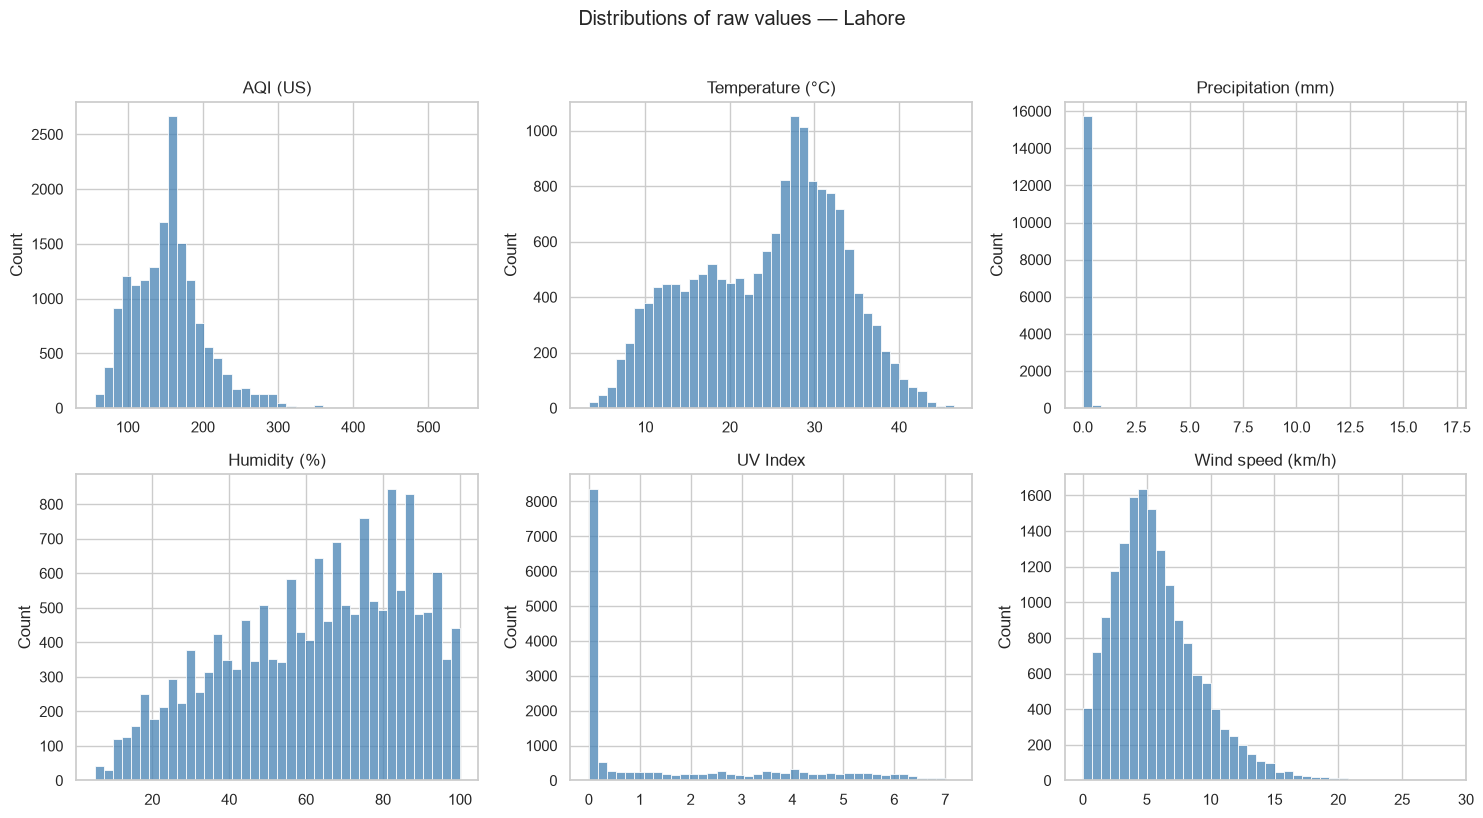

                 count        mean        std   min    25%        50%  \
aqi            16266.0  155.083733  49.692800  56.0  120.0  154.00000   
temperature    16266.0   24.444184   8.657724   3.3   17.5   26.15000   
precipitation  16266.0    0.094479   0.708200   0.0    0.0    0.00000   
humidity       16266.0   62.806590  23.357779   5.0   45.0   66.00000   
uv_index       16266.0    1.549510   2.084334   0.0    0.0    0.09468   
wind_speed     16266.0    5.731348   3.434836   0.0    3.3    5.20000   

                    75%        max  
aqi            179.0000  542.00000  
temperature     30.9000   46.50000  
precipitation    0.0000   17.10000  
humidity        82.0000  100.00000  
uv_index         3.0771    7.17201  
wind_speed       7.5000   28.60000  


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, metric in zip(axes.flat, METRICS):
    field = METRIC_RAW_FIELD[metric]
    sns.histplot(raw[field].dropna(), bins=40, ax=ax, color="steelblue")
    ax.set_title(METRIC_LABEL[metric])
    ax.set_xlabel("")
fig.suptitle("Distributions of raw values — Lahore", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_distributions.png", bbox_inches="tight")
plt.show()

print(raw[[METRIC_RAW_FIELD[m] for m in METRICS]].describe().T)


## 2. Missingness

Two different things, kept separate so one doesn't get mistaken for the other:

1. **Row-level gaps** — hours where we simply have no row at all (e.g. the known Phase 3 backfill hole).
2. **Field-level imputation** — hours where we *do* have a row, but a specific field's value was forward-filled or derived rather than measured directly (the `_source`/`_imputed` columns from `fuse.py`/`backfill.py`).

Expected hourly rows: 17493
Actual rows: 16266
Missing rows: 1227 (7.0%)
Missing range: 2026-09-23 16:00:00 to 2026-11-24 18:00:00


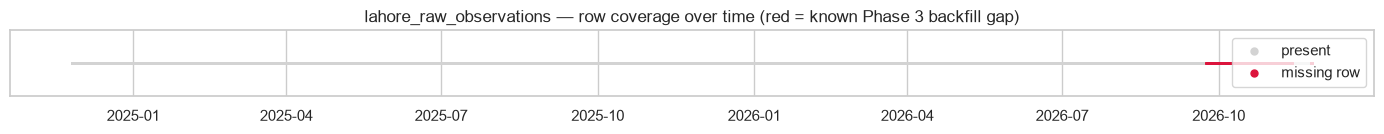

In [4]:
# 1. Row-level gaps: build the full expected hourly index and diff against what we actually have.
expected_hours = pd.date_range(raw["timestamp"].min(), raw["timestamp"].max(), freq="h")
missing_hours = expected_hours.difference(raw["timestamp"])
print(f"Expected hourly rows: {len(expected_hours)}")
print(f"Actual rows: {len(raw)}")
print(f"Missing rows: {len(missing_hours)} ({len(missing_hours) / len(expected_hours):.1%})")
if len(missing_hours):
    print(f"Missing range: {missing_hours.min()} to {missing_hours.max()}")

fig, ax = plt.subplots(figsize=(14, 1.5))
ax.scatter(expected_hours, [1] * len(expected_hours), s=1, color="lightgray", label="present")
if len(missing_hours):
    ax.scatter(missing_hours, [1] * len(missing_hours), s=1, color="crimson", label="missing row")
ax.set_yticks([])
ax.set_title("lahore_raw_observations — row coverage over time (red = known Phase 3 backfill gap)")
ax.legend(loc="upper right", markerscale=5)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02a_row_coverage.png", bbox_inches="tight")
plt.show()


                derived-shortwave  open-meteo
temperature                  0.00      100.00
humidity                     0.00      100.00
precipitation                0.00      100.00
wind_speed                   0.00      100.00
wind_direction               0.00      100.00
uv_index                    98.36        1.64
aqi                          0.00      100.00


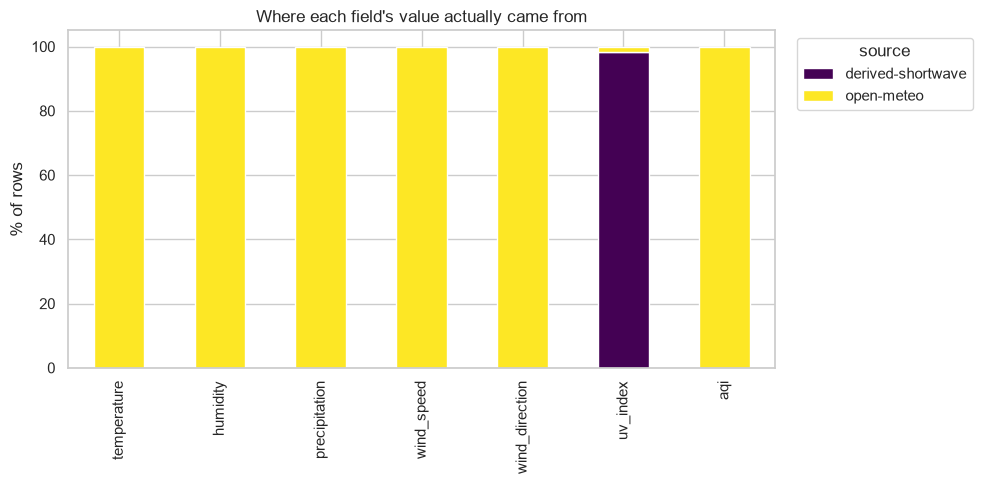

In [5]:
# 2. Field-level imputation: for each field, % of present rows where the value was NOT a direct
# open-meteo measurement (i.e. forward-filled or, for uv_index, derived from shortwave_radiation).
fields = ["temperature", "humidity", "precipitation", "wind_speed", "wind_direction", "uv_index", "aqi"]
source_counts = {}
for field in fields:
    source_counts[field] = raw[f"{field}_source"].value_counts(normalize=True)
source_df = pd.DataFrame(source_counts).fillna(0).T * 100
print(source_df.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
source_df.plot(kind="bar", stacked=True, ax=ax, colormap="viridis")
ax.set_ylabel("% of rows")
ax.set_title("Where each field's value actually came from")
ax.legend(title="source", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02b_field_sources.png", bbox_inches="tight")
plt.show()


## 3. Daily / weekly / seasonal patterns

If these metrics have strong time-of-day or time-of-year structure, that justifies the cyclical hour/day/month encodings already built into `ingestion/features.py` (Phase 2) rather than just hoping a model family finds the pattern on its own.

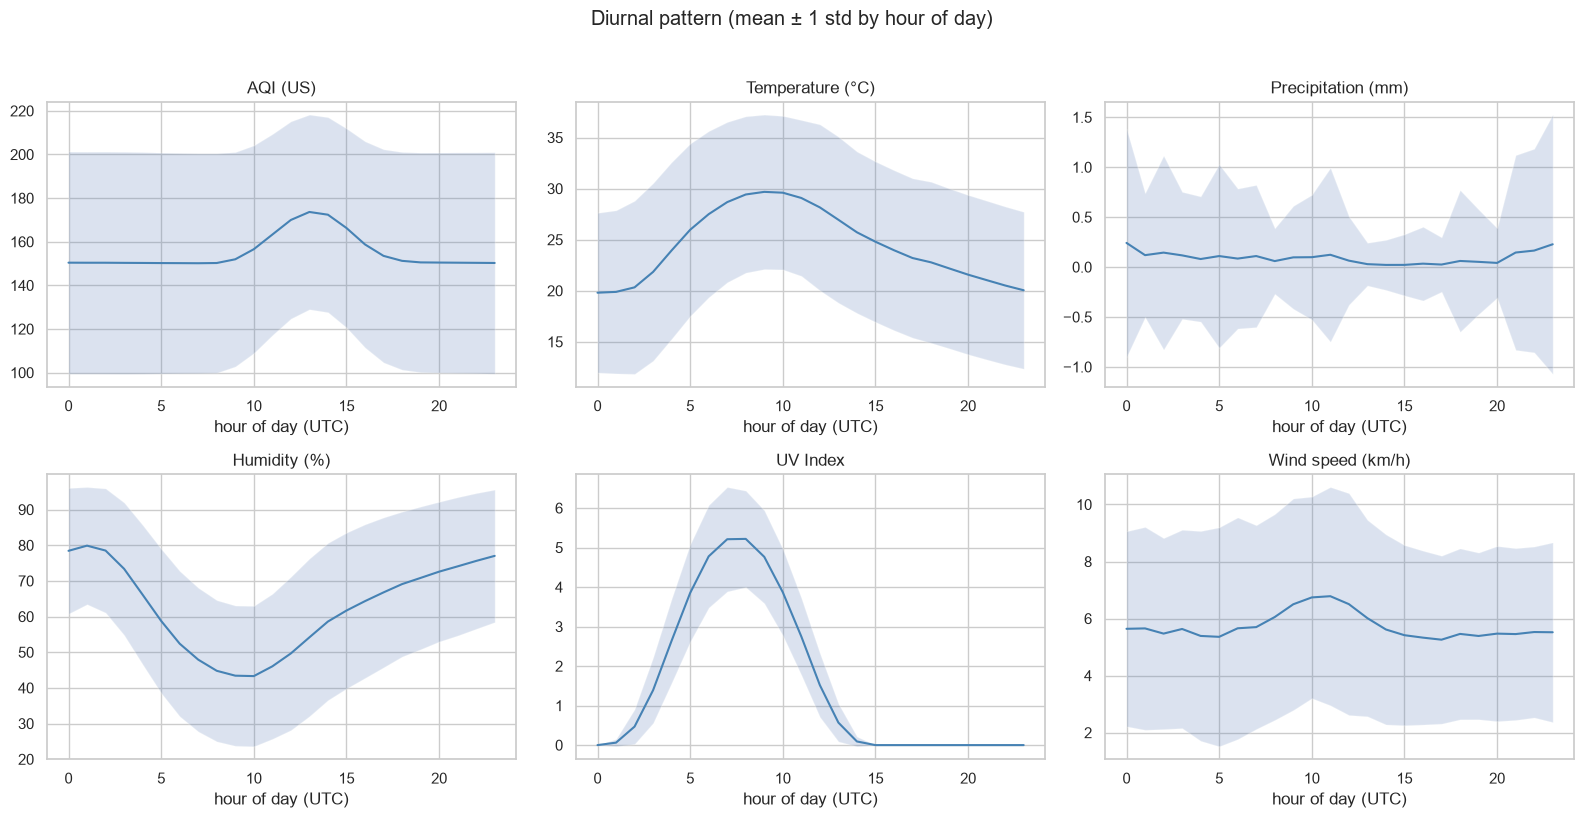

In [6]:
raw["hour"] = raw["timestamp"].dt.hour
raw["dayofweek"] = raw["timestamp"].dt.dayofweek
raw["month"] = raw["timestamp"].dt.month

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, metric in zip(axes.flat, METRICS):
    field = METRIC_RAW_FIELD[metric]
    hourly = raw.groupby("hour")[field].agg(["mean", "std"])
    ax.plot(hourly.index, hourly["mean"], color="steelblue")
    ax.fill_between(hourly.index, hourly["mean"] - hourly["std"], hourly["mean"] + hourly["std"], alpha=0.2)
    ax.set_title(METRIC_LABEL[metric])
    ax.set_xlabel("hour of day (UTC)")
fig.suptitle("Diurnal pattern (mean ± 1 std by hour of day)", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03a_hourly_pattern.png", bbox_inches="tight")
plt.show()


2026-11-26 23:41:22,330 INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-26 23:41:22,385 INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-26 23:41:22,718 INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-26 23:41:22,783 INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-26 23:41:23,230 INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-26 23:41:23,260 INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


... (2 outputs left out)

2026-11-26 23:41:24,082 INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-26 23:41:24,128 INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-26 23:41:24,613 INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-26 23:41:24,646 INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


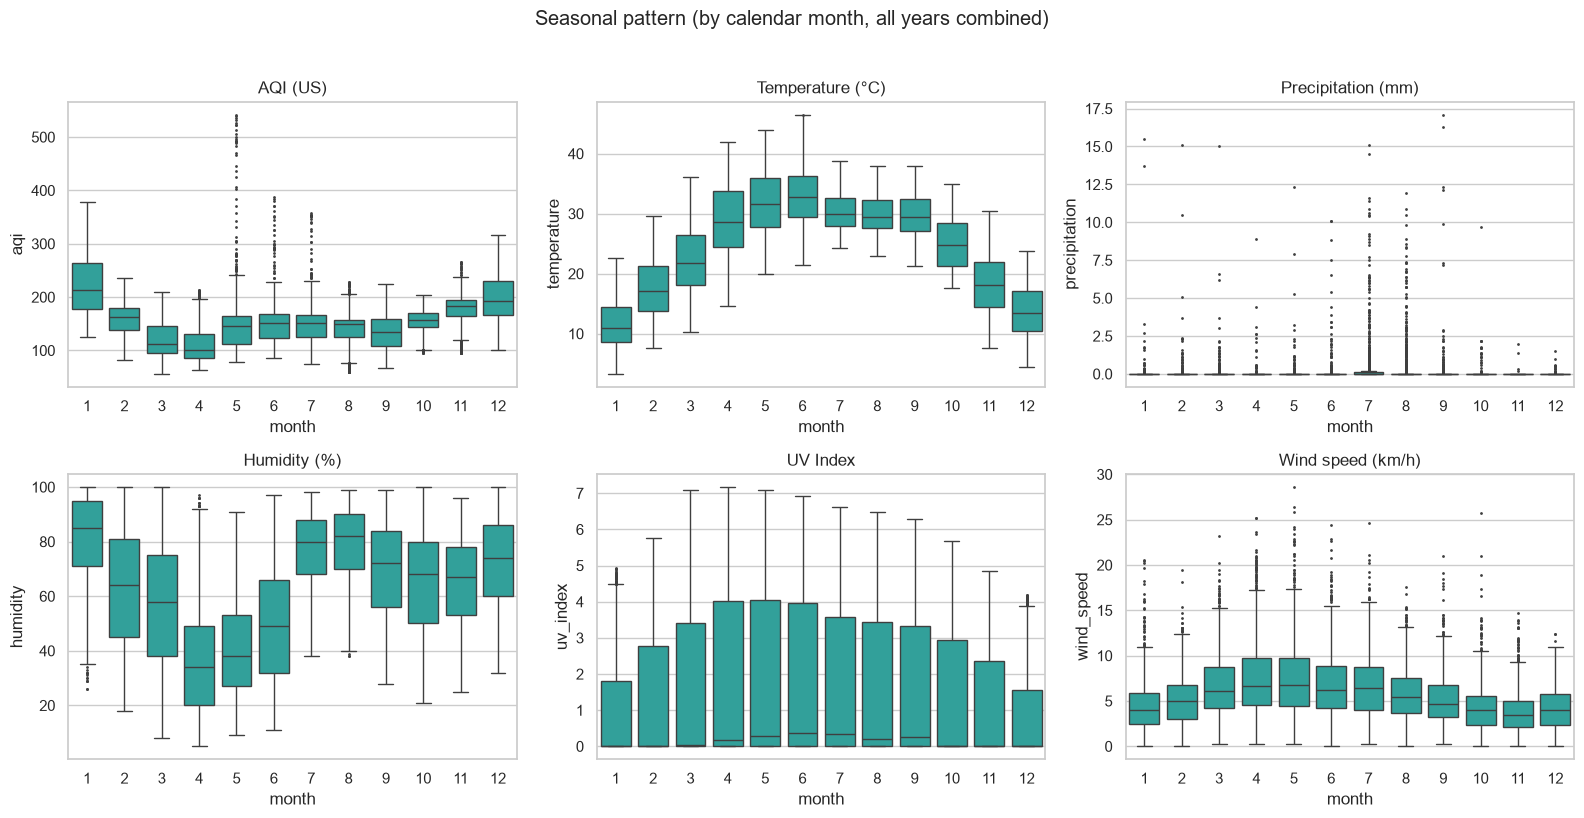

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, metric in zip(axes.flat, METRICS):
    field = METRIC_RAW_FIELD[metric]
    sns.boxplot(data=raw, x="month", y=field, ax=ax, color="lightseagreen", fliersize=1)
    ax.set_title(METRIC_LABEL[metric])
    ax.set_xlabel("month")
fig.suptitle("Seasonal pattern (by calendar month, all years combined)", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03b_monthly_pattern.png", bbox_inches="tight")
plt.show()


## 4. Cross-metric correlation

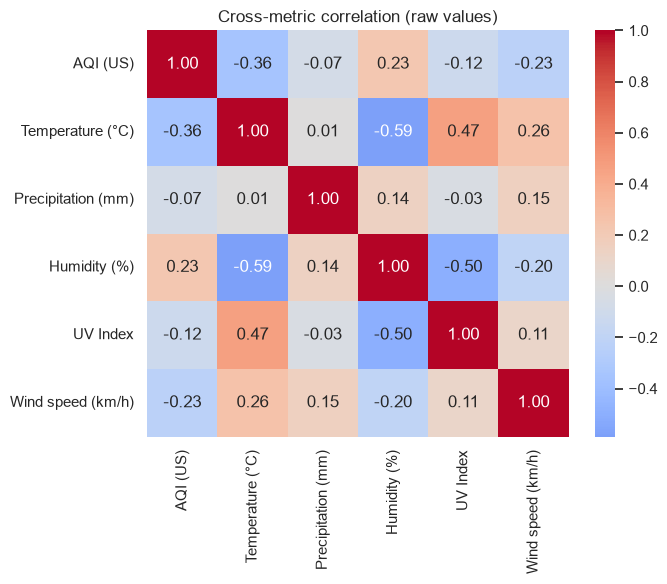

In [8]:
corr_fields = [METRIC_RAW_FIELD[m] for m in METRICS]
corr = raw[corr_fields].corr()
corr.index = corr.columns = [METRIC_LABEL[m] for m in METRICS]

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Cross-metric correlation (raw values)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_correlation.png", bbox_inches="tight")
plt.show()


## 5. Wind direction as a circular quantity

Wind direction is degrees on a compass: 359° and 1° are 2° apart, not 358° apart. A plain arithmetic mean gets this badly wrong, which is exactly why Phase 2's feature engineering never averages raw degrees — it encodes direction as `sin`/`cos` pairs (`wind_direction_sin`/`wind_direction_cos` in `lahore_engineered_features`) instead. The cell below makes that concrete with a real example from this data, then shows a proper wind-rose view.

In [9]:
# Concrete example: hours where the wind is blowing roughly due north (near the 0°/360° seam).
near_north = raw[(raw["wind_direction"] <= 10) | (raw["wind_direction"] >= 350)]["wind_direction"]
naive_mean = near_north.mean()

radians = np.deg2rad(near_north)
circular_mean = np.rad2deg(np.arctan2(np.mean(np.sin(radians)), np.mean(np.cos(radians)))) % 360

print(f"{len(near_north)} near-north readings, e.g.: {sorted(near_north.unique())[:5]} ... {sorted(near_north.unique())[-5:]}")
print(f"Naive arithmetic mean:  {naive_mean:.1f}°  <- wrong: lands near the opposite (south) side")
print(f"Circular (sin/cos) mean: {circular_mean:.1f}°  <- correct: stays near north, where the data actually is")


779 near-north readings, e.g.: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)] ... [np.int64(356), np.int64(357), np.int64(358), np.int64(359), np.int64(360)]
Naive arithmetic mean:  208.6°  <- wrong: lands near the opposite (south) side
Circular (sin/cos) mean: 359.7°  <- correct: stays near north, where the data actually is


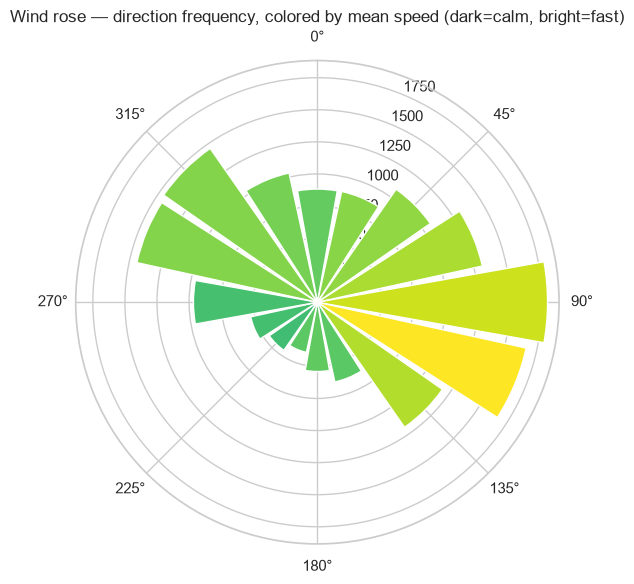

In [10]:
# Wind rose: frequency of wind direction, binned into 16 compass sectors, colored by mean wind speed.
n_sectors = 16
sector_width = 360 / n_sectors
sector = ((raw["wind_direction"] + sector_width / 2) // sector_width % n_sectors).astype(int)
rose = raw.groupby(sector).agg(count=("wind_direction", "size"), mean_speed=("wind_speed", "mean"))
rose = rose.reindex(range(n_sectors), fill_value=0)
angles = np.deg2rad(rose.index * sector_width)

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
bars = ax.bar(angles, rose["count"], width=np.deg2rad(sector_width * 0.9), color=plt.cm.viridis(rose["mean_speed"] / rose["mean_speed"].max()))
ax.set_title("Wind rose — direction frequency, colored by mean speed (dark=calm, bright=fast)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_wind_rose.png", bbox_inches="tight")
plt.show()


## Summary of findings → feeding into Phase 5

- **Diurnal + seasonal structure is real and strong** (temperature and UV index especially, AQI noticeably too) — confirms the cyclical hour/day/month encodings built in Phase 2 are pulling their weight; Phase 5's classical-ML and deep-learning models should benefit from them directly, and the statistical family (SARIMAX/Prophet) should use seasonal terms rather than a plain ARIMA.
- **Cross-metric correlations are meaningful, not noise**: temperature↔humidity is strongly negative (-0.59, unsurprising for Lahore's climate); AQI is negatively correlated with temperature (-0.36) and *positively* with humidity (+0.23) — consistent with Lahore's well-documented winter smog pattern (cooler, more humid conditions coinciding with worse air quality); UV index tracks temperature positively (+0.47) and humidity negatively (-0.50), as expected for sunny/dry vs. overcast/humid hours. Worth keeping these as cross-features for the classical ML models rather than engineering each metric in total isolation.
- **Wind direction must stay encoded as sin/cos**, never as raw degrees — demonstrated concretely above: the naive mean of 779 near-north wind readings lands at 208.6° (south — the opposite side of the compass), while the circular mean correctly lands at 359.7° (north, where the data actually is). Already handled correctly in `ingestion/features.py`.
- **UV Index has a real data-quality caveat**: 98.4% of its values are a *derived* approximation from `shortwave_radiation` (only the most recent ~92 days have a genuine measured value from Open-Meteo's forecast API — every other field is 100% direct `open-meteo` measurement, zero forward-fills needed anywhere in the backfilled history). Phase 5 should flag UV Index model performance as resting on a noisier label for nearly all of its training history, or treat it as a known caveat in the final report rather than a modeling bug if it underperforms.
- **The `lahore_raw_observations` gap is larger than first estimated**: 1,227 missing hours (7.0% of the expected range), from 2026-09-23 16:00 to 2026-11-24 18:00 (~62 days, not the ~51 days first assumed in `PLAN.md` — corrected there too). It's a backfill hole, not sensor missingness, and critically it does **not** appear in `lahore_engineered_features` or `lahore_targets`, which is what `lahore_training_view` (and therefore Phase 5 training) actually reads from. No action needed before Phase 5, but worth closing in a later session for completeness.